# Week 8 Capstone: HCAHPS-Aligned Patient Feedback Agent

## Purpose

Healthcare organizations collect free-form patient comments that provide useful context beyond structured survey responses. Reviewing these comments manually is slow, and different reviewers may assign different categories to the same experience. In this project, I explore an agent that maps supplemental free-text patient feedback to one primary HCAHPS-aligned theme, records the classification, and produces deterministic summaries and visualizations.

This system does not administer the official HCAHPS survey or calculate HCAHPS scores. It uses HCAHPS-aligned themes to organize synthetic narrative feedback. The resulting labels, counts, and percentages describe the comments processed by the agent rather than a hospital's official HCAHPS performance.

The notebook follows the three capstone goals.
*  Part 1 combines components from Weeks 3 through 7 into one classification system. 
* Part 2 evaluates 20 held-out cases with deterministic metrics and LLM-as-judge dimensions for response quality, tool use, and retrieval quality. 
* Part 3 examines one failure trace, identifies the component behavior that contributed to it, and proposes mitigations.

In [1]:
import json
import os
os.environ["MLFLOW_USE_DEFAULT_TRACER_PROVIDER"] = "false"
# Validate one sample before the full evaluation so startup failures surface early.
os.environ["MLFLOW_GENAI_EVAL_SKIP_TRACE_VALIDATION"] = "false"
# Bound concurrent candidate and judge requests to avoid overwhelming remote services.
os.environ["MLFLOW_GENAI_EVAL_MAX_WORKERS"] = "3"

import mlflow
from agent_framework import Agent
from agent_framework.observability import configure_otel_providers
from agent_framework_foundry import FoundryChatClient
from azure.identity import DefaultAzureCredential
from dotenv import load_dotenv
from mlflow.entities import SpanType
from mlflow.entities.trace_location import MlflowExperimentLocation

load_dotenv()

MLFLOW_TRACKING_URI = os.environ["MLFLOW_TRACKING_URI"]
MLFLOW_EXPERIMENT_ID = "14"
ENABLE_SENSITIVE_DATA = os.getenv("ENABLE_SENSITIVE_DATA", "false").lower() == "true"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.tracing.set_destination(MlflowExperimentLocation(MLFLOW_EXPERIMENT_ID))

# Configure Tracing
configure_otel_providers(
    enable_sensitive_data=ENABLE_SENSITIVE_DATA,
)

c:\Users\brett\projects\github\bretttay24\cosc-650-applied-llm-systems\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1: Integrate

The first goal is to combine earlier course components into one system that addresses a real workflow. Patient-experience teams may receive more narrative comments than they can review consistently by hand. This agent retrieves similar labeled examples, classifies each new comment into one HCAHPS-aligned theme, validates and records the result through a tool, and can summarize or visualize the comments processed during a session.

The classification is an organizational aid for supplemental feedback. It does not convert narrative comments into official HCAHPS survey responses or scores.

### Reused Course Components

I reused four components rather than rebuilding the system from scratch:

- **Version-controlled prompting from Week 3** loads the classifier instructions, model, parameters, and prompt version.
- **Schema-validated tool use from Week 4** records each classification and provides deterministic summary and visualization tools.
- **Retrieval-augmented generation from Weeks 5 and 6** searches the local vector index for labeled comments that are similar to the current input.
- **Dynamic few-shot prompting from Week 7** reuses JEV reranking to add relevant retrieved examples to the classification request. The capstone adds a Decision-1 gate so summary and visualization requests bypass retrieval.

The complete component references and classification boundaries are documented in [README.md](./README.md).

In [2]:
# === Load Version Controlled Prompts ===
from prompts.loader import load

classifier_config = load("hcahps-classifier")
print(f"Params: {classifier_config.params}")
print(f"model: {classifier_config.model}")
print(f"Prompt Version: {classifier_config.version}")
print(f"Agent system prompt loaded: {bool(classifier_config.text)}")


# === Load Schema-Validated Tools  ===
from toolbox.get_summary import get_summary
from toolbox.record_classification import record_classification
from toolbox.visualize import plot_distribution

tools = [get_summary, record_classification, plot_distribution]
print(f"Loaded {len(tools)} schema-validated tools: {', '.join(tool.name for tool in tools)}")


# === Configure Dynamic Few-Shot Middleware and Agent ===
from middleware.dynamic_prompting import DynamicPromptingMiddleware

classifier_client = FoundryChatClient(
    project_endpoint=os.getenv("FOUNDRY_PROJECT_ENDPOINT"),
    model=classifier_config.model,
    credential=DefaultAzureCredential(),
)
classifier_client.function_invocation_configuration.update(
    {
        "max_duration_seconds": 30.0,
        "max_function_calls": 6,
        "max_consecutive_errors_per_request": 2,
        "allow_concurrent_invocation": False,
    }
)
classifier_agent = Agent(
    client=classifier_client,
    tools=tools,
    instructions=classifier_config.text,
    middleware=[DynamicPromptingMiddleware()],
)

print()
print(f"Integration complete: classifier agent built: {classifier_agent is not None}")

Params: {'temperature': 0.2, 'reasoning': {'effort': 'low'}}
model: gpt-5.6-luna
Prompt Version: v1
Agent system prompt loaded: True
Loaded 3 schema-validated tools: get_summary, record_classification, plot_distribution

Integration complete: classifier agent built: True


In [3]:
# === Run Agent With MLflow Tracing ===
from toolbox.ledger import get_session_ledger


async def run_classifier(query, session, agent, comment_id=None):
    agent_query = query
    if comment_id is not None:
        agent_query = f"{query}\nUse comment_id {comment_id} when recording this classification."

    with mlflow.tracing.context(session_id=session.session_id):
        with mlflow.start_span(name="classifier_request", span_type=SpanType.CHAIN) as span:
            trace_inputs = {
                "query": query,
                "comment_id": comment_id,
                "prompt_name": classifier_config.name,
                "prompt_version": classifier_config.version,
            }
            if ENABLE_SENSITIVE_DATA:
                trace_inputs["system_prompt"] = classifier_config.text
            span.set_inputs(trace_inputs)
            span.set_attributes({
                "prompt.name": classifier_config.name,
                "prompt.version": classifier_config.version,
                "prompt.model": classifier_config.model,
                "prompt.params": json.dumps(classifier_config.params),
            })

            response = await agent.run(agent_query, session=session)
            outputs = {"response": response.text}
            if comment_id is not None:
                prediction = get_session_ledger(session).get(comment_id)
                outputs.update({
                    "predicted_label": prediction["label"],
                    "predicted_confidence": prediction["confidence"],
                    "predicted_rationale": prediction["rationale"],
                })
            span.set_outputs(outputs)
            trace_id = span.trace_id

    return response, trace_id


example = """
{
    "id": 18,
    "input": "My doctor was kind, but I went home not knowing why I needed the new heart medicine.",
    "expected": {
        "label": "care_transition",
        "rationale": "Despite the kind doctor, the patient went home without understanding the new heart medicine's purpose, indicating inadequate preparation for self-care.",
        "confidence": "medium",
    },
}
"""

query = """
help me classify this input:
    "id": 18,
    "input": "My doctor was kind, but I went home not knowing why I needed the new heart medicine."
"""

### Example Working Query

In [4]:
# === Run Example Query ===
mlflow.tracing.disable_notebook_display()
example_session = classifier_agent.create_session()
response1, example_trace_id = await run_classifier(
    query,
    example_session,
    classifier_agent,
)

In [5]:
from textwrap import fill

# === Display Example Query ===
divider = "=" * 80

print(divider)
print("Integrated System Example Response to Query".center(80))
print(divider)
print()
print("[User Query]")
print(fill(query.strip(), width=80, initial_indent="    ", subsequent_indent="    "))
print()
print("[Agent Response]")
print(fill(response1.text, width=80, initial_indent="    ", subsequent_indent="    "))
print()

                  Integrated System Example Response to Query                   

[User Query]
    help me classify this input:     "id": 18,     "input": "My doctor was kind,
    but I went home not knowing why I needed the new heart medicine."

[Agent Response]
    {"label":"care_transition","confidence":"high","rationale":"The patient went
    home without understanding why the new heart medicine was needed, indicating
    inadequate understanding of medication at discharge."}  Recorded
    classification for comment 18.



## Part 2: Evaluate the Agent

The second goal is to measure the integrated system on a small held-out set. I run the agent once for each of 20 synthetic patient comments and attach the expected label, confidence, and response to the corresponding MLflow trace.

I use deterministic metrics for exact label accuracy, confidence agreement, and retrieval label coverage. I then use MLflow LLM-as-judge scorers across three named dimensions. Response quality measures correctness and relevance to the query. Tool use measures call correctness and efficiency. Retrieval quality measures the relevance of the few-shot examples and whether the response is grounded in them. The judges evaluate the stored traces, so the agent is not rerun for each scoring pass.

### Evaluation Setup
#### Load Dataset
Load the held-out JSONL as MLflow evaluation rows for direct sequential classification.

In [6]:
from pathlib import Path

from evaluations.classification_dataset import load_classification_dataset

# === Convert the Jsonl file to mlflow eval dataset format ===
held_out_data = load_classification_dataset(Path("data/hcahps_synthetic_test.jsonl"))


mlflow.set_experiment(experiment_id=MLFLOW_EXPERIMENT_ID)

print(f"Loaded {len(held_out_data)} held-out MLflow evaluation rows.")

Loaded 20 held-out MLflow evaluation rows.


#### Configure Sequential Evaluation

In [7]:
# === Attach Held-Out Expectations to Each Trace ===
def log_trace_expectations(trace_id: str, expectations: dict) -> None:
    for name in ("expected_response", "expected_label", "expected_confidence"):
        mlflow.log_expectation(
            trace_id=trace_id,
            name=name,
            value=expectations[name],
            metadata={"dataset": "hcahps_synthetic_test"},
        )


print("Sequential evaluation configured with explicit trace expectations.")

Sequential evaluation configured with explicit trace expectations.


### Deterministic Evaluations

The notebook classifies each held-out row sequentially with a fresh Agent Framework session. It records the tool-validated prediction, attaches the held-out expectations to that row's MLflow trace, and calculates four deterministic metrics without using an MLflow prediction function.

- `'label_exact_match'`: Checks whether the predicted HCAHPS label exactly matches the expected label.
- `'confidence_exact_match'`: Checks whether the predicted confidence level exactly matches the expected confidence.
- `'retrieval_label_hit_at_3'`: Checks whether the expected label appears among the first three retrieved examples.
- `'retrieval_label_matches_at_3'`: Counts how many of the first three retrieved examples have the expected label.

In [8]:
# === Prepare Sequential Evaluation State ===
classification_rows = []

print(f"Prepared to classify {len(held_out_data)} held-out rows sequentially.")

Prepared to classify 20 held-out rows sequentially.


In [9]:
# === Run Sequential Deterministic Evaluation ===
mlflow.autolog(disable=True)
print("Starting sequential deterministic evaluation...", flush=True)

for row_number, row in enumerate(held_out_data, start=1):
    inputs = row["inputs"]
    expectations = row["expectations"]
    comment_id = inputs["comment_id"]

    print(
        f"[classification] Starting row={row_number}/{len(held_out_data)} "
        f"comment_id={comment_id}",
        flush=True,
    )
    case_session = classifier_agent.create_session()
    response, trace_id = await run_classifier(
        inputs["query"],
        case_session,
        classifier_agent,
        comment_id=comment_id,
    )
    prediction = get_session_ledger(case_session).get(comment_id)
    if mlflow.get_trace(trace_id, flush=True) is None:
        raise RuntimeError(f"MLflow trace not found after classification: {trace_id}")
    log_trace_expectations(trace_id, expectations)

    classification_rows.append(
        {
            "comment_id": comment_id,
            "query": inputs["query"],
            "response": response.text,
            "predicted_label": prediction["label"],
            "predicted_confidence": prediction["confidence"],
            "predicted_rationale": prediction["rationale"],
            "expected_label": expectations["expected_label"],
            "expected_confidence": expectations["expected_confidence"],
            "trace_id": trace_id,
        }
    )
    print(
        f"[classification] Completed comment_id={comment_id} "
        f"label={prediction['label']}",
        flush=True,
    )

print(f"Sequential evaluation completed for {len(classification_rows)} rows.", flush=True)

Starting sequential deterministic evaluation...
[classification] Starting row=1/20 comment_id=1
[classification] Completed comment_id=1 label=communication_nurses
[classification] Starting row=2/20 comment_id=2
[classification] Completed comment_id=2 label=communication_nurses
[classification] Starting row=3/20 comment_id=3
[classification] Completed comment_id=3 label=communication_nurses
[classification] Starting row=4/20 comment_id=4
[classification] Completed comment_id=4 label=communication_doctors
[classification] Starting row=5/20 comment_id=5
[classification] Completed comment_id=5 label=communication_doctors
[classification] Starting row=6/20 comment_id=6
[classification] Completed comment_id=6 label=staff_responsiveness
[classification] Starting row=7/20 comment_id=7
[classification] Completed comment_id=7 label=staff_responsiveness
[classification] Starting row=8/20 comment_id=8
[classification] Completed comment_id=8 label=communication_medicines
[classification] Starting r

In [10]:
# === Validate Sequential Evaluation Results ===
if len(classification_rows) != len(held_out_data):
    raise RuntimeError(
        f"Expected {len(held_out_data)} classifications, but collected {len(classification_rows)}."
    )

print(f"Validated {len(classification_rows)} classifications.")

Validated 20 classifications.


In [11]:
# === Load Classification Traces and Calculate Deterministic Metrics ===
classification_traces = []

for result in classification_rows:
    trace_id = result["trace_id"]
    trace = mlflow.get_trace(trace_id, flush=True)
    if trace is None:
        raise RuntimeError(f"MLflow trace not found: {trace_id}")
    classification_traces.append(trace)

    middleware_spans = trace.search_spans(name="dynamic_prompting")
    if not middleware_spans:
        raise RuntimeError(f"Trace {trace_id} has no dynamic_prompting span.")
    retrieved_labels = list((middleware_spans[-1].outputs or {}).get("retrieved_labels", []))[:3]

    expected_label = result["expected_label"]
    result["retrieved_labels"] = retrieved_labels
    result["label_exact_match"] = result["predicted_label"] == expected_label
    result["confidence_exact_match"] = (
        result["predicted_confidence"] == result["expected_confidence"]
    )
    result["retrieval_label_hit_at_3"] = expected_label in retrieved_labels
    result["retrieval_label_matches_at_3"] = sum(
        label == expected_label for label in retrieved_labels
    )

row_count = len(classification_rows)
deterministic_metrics = {
    "label_exact_match/mean": sum(row["label_exact_match"] for row in classification_rows) / row_count,
    "confidence_exact_match/mean": sum(row["confidence_exact_match"] for row in classification_rows) / row_count,
    "retrieval_label_hit_at_3/mean": sum(row["retrieval_label_hit_at_3"] for row in classification_rows) / row_count,
    "retrieval_label_matches_at_3/mean": sum(row["retrieval_label_matches_at_3"] for row in classification_rows) / row_count,
}

print(f"Loaded and scored {len(classification_traces)} classification traces.")

Loaded and scored 20 classification traces.


In [12]:
# === Display Deterministic Evaluation Results ===
deterministic_metrics

{'label_exact_match/mean': 1.0,
 'confidence_exact_match/mean': 0.95,
 'retrieval_label_hit_at_3/mean': 1.0,
 'retrieval_label_matches_at_3/mean': 2.45}

#### Deterministic Performance Dashboard

The dashboard summarizes the four deterministic metrics returned by MLflow.

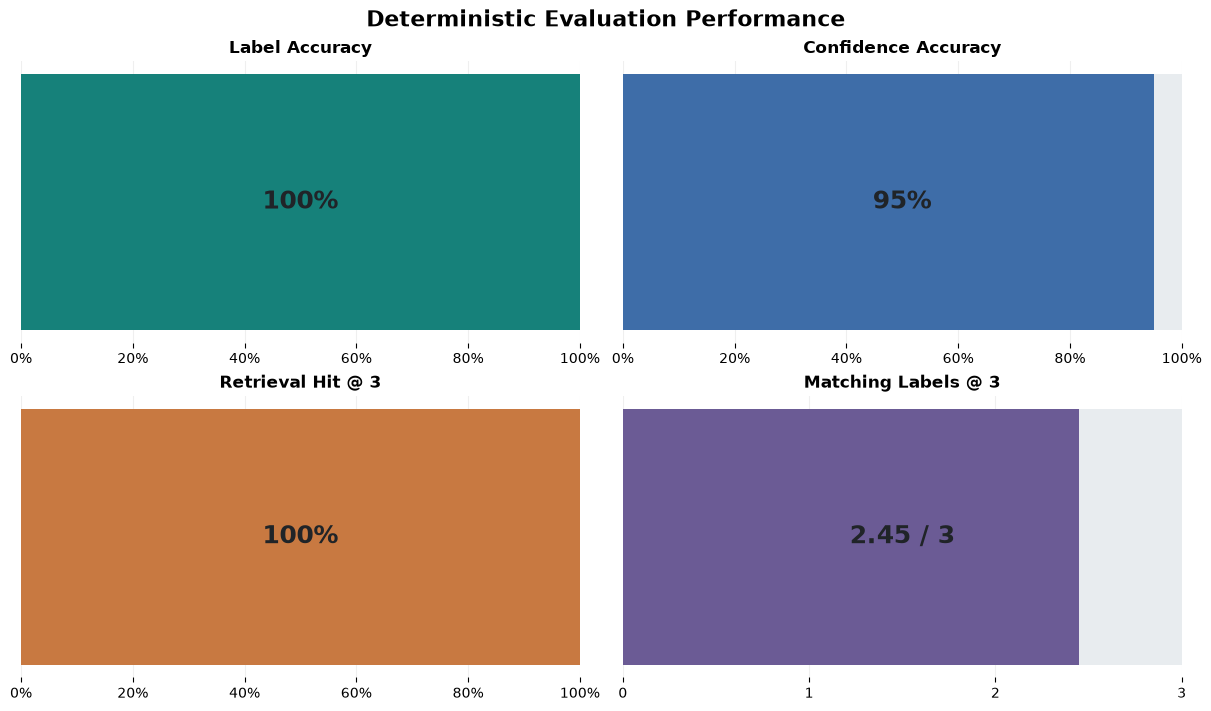

In [13]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

metric_specs = [
    ("label_exact_match/mean", "Label Accuracy", 1.0, "#16817A"),
    ("confidence_exact_match/mean", "Confidence Accuracy", 1.0, "#3E6DA8"),
    ("retrieval_label_hit_at_3/mean", "Retrieval Hit @ 3", 1.0, "#C87941"),
    ("retrieval_label_matches_at_3/mean", "Matching Labels @ 3", 3.0, "#6B5B95"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
fig.suptitle("Deterministic Evaluation Performance", fontsize=16, fontweight="bold")

for axis, (metric_key, title, maximum, color) in zip(axes.flat, metric_specs):
    value = float(deterministic_metrics[metric_key])
    axis.barh([0], [maximum], color="#E8ECEF", height=0.5)
    axis.barh([0], [value], color=color, height=0.5)
    axis.set_xlim(0, maximum)
    axis.set_yticks([])
    axis.set_title(title, fontsize=12, fontweight="bold")
    axis.grid(axis="x", alpha=0.2)
    axis.set_axisbelow(True)

    if maximum == 1.0:
        axis.xaxis.set_major_formatter(PercentFormatter(1.0))
        value_label = f"{value:.0%}"
    else:
        axis.set_xticks(range(int(maximum) + 1))
        value_label = f"{value:.2f} / {maximum:.0f}"

    axis.text(
        0.5,
        0.5,
        value_label,
        transform=axis.transAxes,
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold",
        color="#202428",
    )
    for spine in axis.spines.values():
        spine.set_visible(False)

plt.show()

**Deterministic Evaluation Analysis**

`label_exact_match` directly measures classification accuracy against the held-out labels. This run classified every label correctly. `confidence_exact_match` compares the model's confidence with the synthetic expected confidence. A slightly lower score indicates disagreement about certainty rather than the theme itself. The two retrieval-label metrics are supporting diagnostics. Hit at 3 checks whether any retrieved example shares the expected label. Matching labels at 3 counts how many do. Vector search selects candidates by semantic similarity, and JEV reranks them by estimated relevance to the comment. Neither stage uses the held-out ground-truth label. Matching labels are therefore a useful side effect rather than the retrieval objective. The result of 2.45 matching labels among three examples suggests that relevant comments often share a theme without requiring every retrieved example to have the expected label.

### LLM-as-Judge Evaluations

The native MLflow judges score the traces generated by the deterministic evaluation. The candidate agent is not invoked again.

#### Response Quality Evaluations

* `Correctness` compares each response with its `expected_response`.
* `RelevanceToQuery` assesses whether the response addresses the classification request.

In [14]:
# === Configure LLM Judges ===
from mlflow.genai.scorers import (
    Correctness,
    RelevanceToQuery,
    RetrievalGroundedness,
    RetrievalRelevance,
    ToolCallCorrectness,
    ToolCallEfficiency,
)

JUDGE_MODEL_URI = "azure:/gpt-5-mini"
os.environ["AZURE_API_BASE"] = os.environ["FOUNDRY_PROJECT_ENDPOINT"].split("/api/projects", maxsplit=1)[0].rstrip("/")

In [15]:
# === Run Response Quality Judges ===
with mlflow.start_run(run_name="Response quality judges"):
    response_quality_results = mlflow.genai.evaluate(
        data=classification_traces,
        scorers=[
            Correctness(model=JUDGE_MODEL_URI),
            RelevanceToQuery(model=JUDGE_MODEL_URI),
        ],
    )

response_quality_results.metrics

Evaluating: 100%|██████████| 20/20 [Elapsed: 00:24, Remaining: 00:00] [predict_fn: 0%, scorers: 100%]


{'relevance_to_query/mean': np.float64(1.0),
 'correctness/mean': np.float64(0.95)}

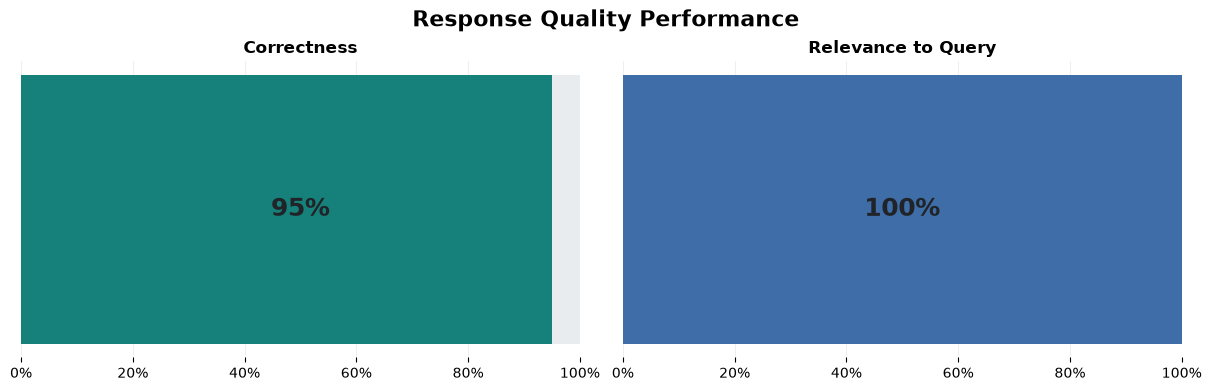

In [16]:
# === Display Response Quality Performance ===
response_metric_specs = [
    ("correctness/mean", "Correctness", "#16817A"),
    ("relevance_to_query/mean", "Relevance to Query", "#3E6DA8"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
fig.suptitle("Response Quality Performance", fontsize=16, fontweight="bold")

for axis, (metric_key, title, color) in zip(axes, response_metric_specs):
    value = float(response_quality_results.metrics[metric_key])
    axis.barh([0], [1.0], color="#E8ECEF", height=0.5)
    axis.barh([0], [value], color=color, height=0.5)
    axis.set_xlim(0, 1)
    axis.set_yticks([])
    axis.set_title(title, fontsize=12, fontweight="bold")
    axis.xaxis.set_major_formatter(PercentFormatter(1.0))
    axis.grid(axis="x", alpha=0.2)
    axis.set_axisbelow(True)
    axis.text(
        0.5,
        0.5,
        f"{value:.0%}",
        transform=axis.transAxes,
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold",
        color="#202428",
    )
    for spine in axis.spines.values():
        spine.set_visible(False)

plt.show()

**Response Quality Analysis**

These scores come from LLM-as-judge evaluations. They reflect the judge model's interpretation and may vary slightly between runs. Relevance indicates whether the response addresses the classification request. Correctness compares the complete natural-language response with the expected response. The lower correctness score should be interpreted alongside the deterministic result. The classifier achieved 100% label accuracy in this run. The judge is therefore likely reacting to differences in explanation, wording, or confidence rather than an incorrect HCAHPS theme. The judge scores add useful qualitative evidence. The deterministic label match remains the stronger measure of classification accuracy.

#### Tool Use Evaluations

* `ToolCallCorrectness` judges whether the recorded tool calls and arguments fit each classification request.
* `ToolCallEfficiency` identifies redundant or unnecessary calls from the trace's native `TOOL` spans.

In [17]:
# === Run Tool Use Judges ===
with mlflow.start_run(run_name="Tool call judges"):
    tool_call_results = mlflow.genai.evaluate(
        data=classification_traces,
        scorers=[
            ToolCallCorrectness(model=JUDGE_MODEL_URI),
            ToolCallEfficiency(model=JUDGE_MODEL_URI),
        ],
    )

tool_call_results.metrics

Evaluating: 100%|██████████| 20/20 [Elapsed: 01:13, Remaining: 00:00] [predict_fn: 0%, scorers: 100%]


{'tool_call_efficiency/mean': np.float64(1.0),
 'tool_call_correctness/mean': np.float64(1.0)}

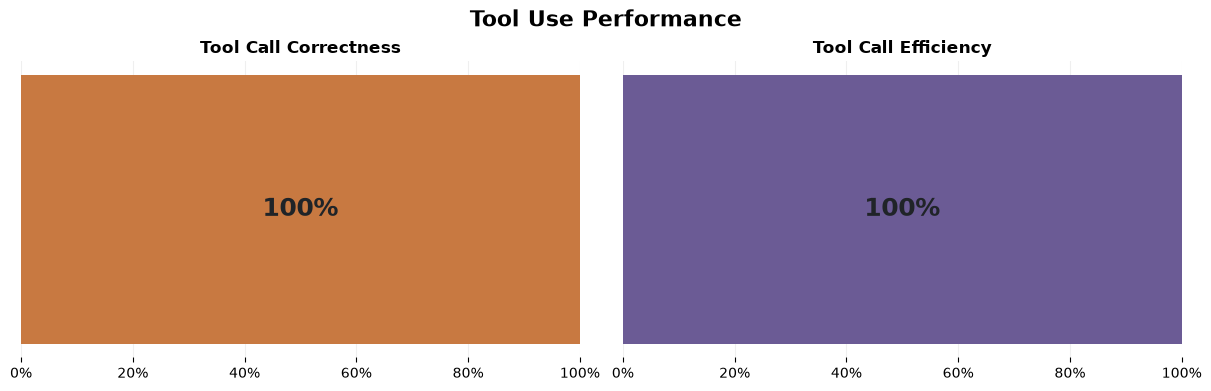

In [18]:
# === Display Tool Use Performance ===
tool_metric_specs = [
    ("tool_call_correctness/mean", "Tool Call Correctness", "#C87941"),
    ("tool_call_efficiency/mean", "Tool Call Efficiency", "#6B5B95"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
fig.suptitle("Tool Use Performance", fontsize=16, fontweight="bold")

for axis, (metric_key, title, color) in zip(axes, tool_metric_specs):
    value = float(tool_call_results.metrics[metric_key])
    axis.barh([0], [1.0], color="#E8ECEF", height=0.5)
    axis.barh([0], [value], color=color, height=0.5)
    axis.set_xlim(0, 1)
    axis.set_yticks([])
    axis.set_title(title, fontsize=12, fontweight="bold")
    axis.xaxis.set_major_formatter(PercentFormatter(1.0))
    axis.grid(axis="x", alpha=0.2)
    axis.set_axisbelow(True)
    axis.text(
        0.5,
        0.5,
        f"{value:.0%}",
        transform=axis.transAxes,
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold",
        color="#202428",
    )
    for spine in axis.spines.values():
        spine.set_visible(False)

plt.show()

**Tool Use Analysis**

Tool-call correctness and efficiency are also LLM-as-judge scores derived from the recorded trace. Correctness considers whether the agent selected the appropriate tool and supplied valid arguments. Efficiency considers whether the call sequence contained unnecessary or repeated work. The strong scores indicate that the classifier generally records each result with the expected schema and without redundant calls. These judges depend on the trace structure. They should be read as evidence about the observed tool workflow rather than deterministic proof of every possible execution path.

**This evaluation set contains only classification tasks.** It measures the agent's use of `record_classification` but does not test `get_summary` or `plot_distribution`. Within this scope, the LLM judges rated every observed `record_classification` call as correct and efficient.

#### Dynamic Few-Shot Retrieval Evaluations

* `RetrievalRelevance` uses an LLM judge to assess whether each of the three retrieved examples is semantically useful for the input query. It does not compare retrieved labels with the expected label.
* `retrieval_relevance/precision` is calculated per request as the number of examples judged relevant divided by the number retrieved. With three examples, possible scores include `1.0` (3/3), `0.667` (2/3), `0.333` (1/3), and `0.0` (0/3).
* `retrieval_relevance/mean` averages all example-level relevance judgments, while `retrieval_relevance/precision/mean` averages the per-request precision scores. These means are equal when every request retrieves the same number of examples, but they can differ when retrieval counts vary.
* `RetrievalGroundedness` uses an LLM judge to assess whether each classification response is supported by the retrieved examples.

Both judges consume the final-context `RETRIEVER` span and should be interpreted as model-based assessments rather than deterministic ground-truth measurements.

In [19]:
# === Run Dynamic Few-Shot Judges ===
with mlflow.start_run(run_name="Dynamic few-shot judges"):
    dynamic_few_shot_results = mlflow.genai.evaluate(
        data=classification_traces,
        scorers=[
            RetrievalRelevance(model=JUDGE_MODEL_URI),
            RetrievalGroundedness(model=JUDGE_MODEL_URI),
        ],
    )


Evaluating: 100%|██████████| 20/20 [Elapsed: 01:25, Remaining: 00:00] [predict_fn: 0%, scorers: 100%]


In [20]:
dynamic_few_shot_results.metrics

{'retrieval_groundedness/mean': np.float64(0.55),
 'retrieval_relevance/precision/mean': np.float64(0.9666666666666668),
 'retrieval_relevance/mean': np.float64(0.9666666666666667)}

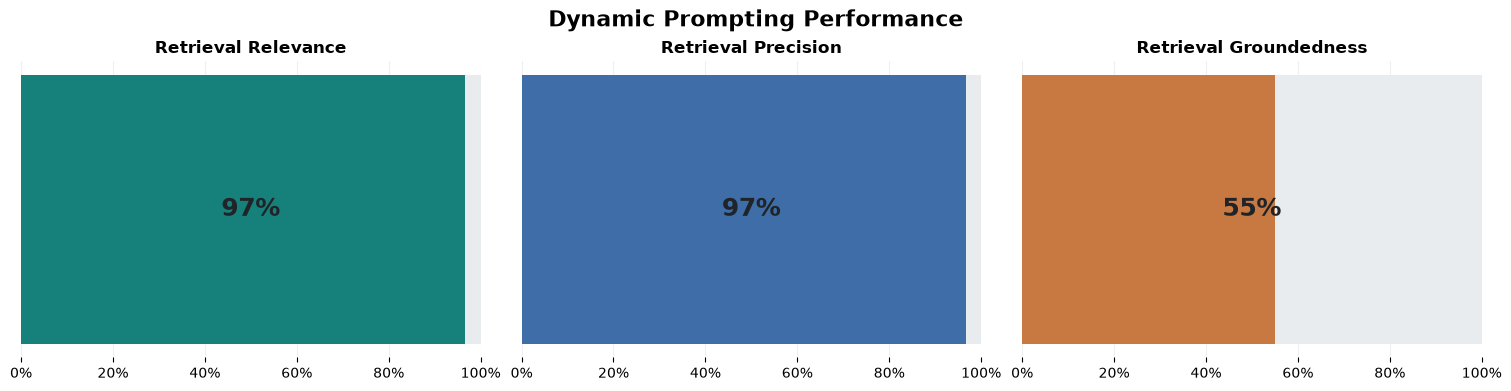

In [21]:
# === Display Dynamic Prompting Performance ===
dynamic_prompting_metric_specs = [
    ("retrieval_relevance/mean", "Retrieval Relevance", "#16817A"),
    ("retrieval_relevance/precision/mean", "Retrieval Precision", "#3E6DA8"),
    ("retrieval_groundedness/mean", "Retrieval Groundedness", "#C87941"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
fig.suptitle("Dynamic Prompting Performance", fontsize=16, fontweight="bold")

for axis, (metric_key, title, color) in zip(axes, dynamic_prompting_metric_specs):
    value = float(dynamic_few_shot_results.metrics[metric_key])
    axis.barh([0], [1.0], color="#E8ECEF", height=0.5)
    axis.barh([0], [value], color=color, height=0.5)
    axis.set_xlim(0, 1)
    axis.set_yticks([])
    axis.set_title(title, fontsize=12, fontweight="bold")
    axis.xaxis.set_major_formatter(PercentFormatter(1.0))
    axis.grid(axis="x", alpha=0.2)
    axis.set_axisbelow(True)
    axis.text(
        0.5,
        0.5,
        f"{value:.0%}",
        transform=axis.transAxes,
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold",
        color="#202428",
    )
    for spine in axis.spines.values():
        spine.set_visible(False)

plt.show()

**Dynamic Few-Shot Retrieval Analysis**

Retrieval relevance and precision are LLM-judge assessments of whether the retrieved examples are semantically useful for each query. They are not based on whether the examples share the held-out ground-truth label. The deterministic finding of roughly 2.5 matching labels among the three retrieved examples supports the same overall trend. Label agreement remains a side effect of semantic similarity rather than the retrieval target. Groundedness asks a different question. It measures whether the final response is supported by those examples. A lower groundedness score can occur even when relevance is strong. The retriever must choose three neighbors from only 80 synthetic training comments. This limits the variety and closeness of the available context. These model-judged scores may vary across runs. Together they suggest that retrieval usually finds useful examples while the available synthetic context does not always fully support the generated rationale.

## Part 3: Failure Case and Explanation

The third goal is to use trace evidence to explain one system weakness and propose a mitigation. I selected a held-out case that received the correct HCAHPS-aligned theme but missed the expected confidence level. The case also received negative assessments from response correctness and retrieval groundedness.

The native MLflow trace below shows the complete execution path. The analysis compares the expected and observed classifications, preserves the exact dynamic few-shot context and judge explanations, examines how retrieval reranking and confidence calibration may have contributed to the result, and identifies targeted improvements.

**Selected trace**

`tr-aa06aeb4814895e7d7e58ccc05bfa3b3`

In [22]:
from IPython.display import HTML, display
from mlflow.tracing.display import get_notebook_iframe_html

mlflow.tracing.disable_notebook_display()
trace = mlflow.get_trace("tr-aa06aeb4814895e7d7e58ccc05bfa3b3")

trace_ui_html = get_notebook_iframe_html([trace])
trace_ui_html = trace_ui_html.replace(
    "<iframe\n",
    '<div style="height: 600px; overflow-y: auto;">\n  <iframe\n',
)
trace_ui_html = trace_ui_html.replace("height: 500px;", "height: 1400px;")
trace_ui_html = trace_ui_html.replace(
    "  />\n</div>",
    "  ></iframe>\n</div>\n</div>",
)

display(HTML(trace_ui_html))

### Failure Evidence and Analysis

**MLflow Trace ID**

`tr-aa06aeb4814895e7d7e58ccc05bfa3b3`

### Failure Case

**Input**

"Classify this patient comment: unfamiliar patch appeared on my arm and idk who put it there or what it was for"


**Expected classification**

```json
{
  "label": "communication_medicines",
  "rationale": "A medicine patch was applied during the stay without explaining what it was or its purpose.",
  "confidence": "high"
}
```

**Actual classification**

```text
Label: communication_medicines
Confidence: Medium
Rationale: The patient found an unfamiliar patch and was not told what it was for, indicating inadequate explanation of a treatment or medication during the stay.
```

##### Retrieved Dynamic Few-Shot Context

The middleware supplied the following context:

```text
"""

=== DYNAMIC FEW-SHOT CLASSIFICATION EXAMPLES ===
--- Example 1 --- Query: Classify this patient comment: I knew how to change the dressing, yet no one explained when a change in its appearance required a call. Answer: {"label":"discharge_information","rationale":"The patient knew the care task but lacked instructions about warning signs requiring contact.","confidence":"high"}
--- Example 2 --- Query: Classify this patient comment: A nurse handed me an unfamiliar capsule during the stay and only said it was on the list. Answer: {"label":"communication_medicines","rationale":"An unfamiliar medicine was given during the stay without explaining its purpose.","confidence":"high"}
--- Example 3 --- Query: Classify this patient comment: new med showed up at breakfast, no one sed why i needed it Answer: {"label":"communication_medicines","rationale":"A new medicine was given during the hospital stay without its purpose being explained.","confidence":"high"}
=== END FEW-SHOT EXAMPLES ===
=== ORIGINAL USER QUERY === Classify this patient comment: unfamiliar patch appeared on my arm and idk who put it there or what it was for Use comment_id 9 when recording this classification. === END ORIGINAL USER QUERY ===

"""
```

##### LLM-as-Judge Assessments

**Response correctness explanation**

```text
"Rationale
Let's think step by step: The document includes the comment that an unfamiliar patch appeared and the patient did not know who put it there or what it was for, which supports labeling this as communication_medicines and matches the claim's rationale. However, the document records the confidence as 'medium' for that classification, so the claim's assertion of 'high' confidence is not supported.
Source
azure:/gpt-5-mini"
```

**Retrieval groundedness explanation**

```text
"Rationale
Let's think step by step: The document contains example classifications for similar comments (unfamiliar capsule, new med) labeled as communication_medicines with high confidence, but it does not show or record the specific comment about an unfamiliar patch nor the claimed recording of comment 9. Therefore the claim that comment 9 was recorded as communication_medicines with medium confidence and the given rationale is not supported by the document.
Source
azure:/gpt-5-mini" 
```

### Failure Analysis

This case shows that my dynamic prompting pipeline, which retrieves few-shot examples and reranks them with JEV, can select a misleading top example when the input is ambiguous. It also shows that evaluations produced by LLM judges require careful interpretation.

The predicted label matched the expected `communication_medicines` label. The rationale also identified the central issue. The patient received an unfamiliar medicine or treatment without an explanation. The deterministic label check therefore passed, even though the confidence check did not.

The reranking issue appears to stem from ambiguity in the word `patch`. The highest-ranked example described a dressing and was labeled `discharge_information`. JEV may have prioritized the semantic association between a patch and a dressing even though the example represented the wrong HCAHPS theme. The other two retrieved examples had the correct `communication_medicines` label, but they described unexplained capsules or medications rather than a patch. In clinical practice, medication patches may deliver nicotine, fentanyl, or scopolamine. However, my initial interpretation was also that the patch might refer to a bandage. This ambiguity may help explain both the misleading top-ranked example and the agent's lower confidence.

The remaining failure was a confidence mismatch. The expected confidence was `high`, while the agent recorded `medium`. The agent may have treated uncertainty about whether the patch was a medicine or another treatment as a reason to lower confidence. This interpretation is consistent with the mixture of one misleading dressing example and two relevant medication examples in the retrieved context.

The judge assessments expose a separate evaluation problem. The response-correctness judge supported the label and rationale but rejected the expected `high` confidence because the recorded output was `medium`. The retrieval-groundedness judge recognized that the medication examples were similar, but those examples did not contain the exact patch comment or prove that comment 9 had been recorded. The response was relevant and correctly labeled, but its complete claim was not directly supported by the retrieved examples.

This case suggests two system improvements and one evaluation caution. The retrieval and reranking pipeline needs examples that distinguish medicine patches from wound dressings. The prompt should also define when a clear label can receive `high` confidence despite uncertainty about the exact treatment type. The judge scores should be interpreted alongside deterministic label and confidence checks rather than treated as standalone ground truth.

### Mitigation

I would address this failure before classification rather than forcing the expected label or confidence after the agent responds.

First, I would add contrastive training examples that clearly separate medication patches from wound dressings. A medication-patch example would focus on receiving an unexplained medicine during the stay. A wound-dressing example would focus on discharge instructions, dressing changes, or warning signs. These examples would give vector retrieval closer matches for both meanings of `patch`.

Second, I would make the JEV reranking question specific to classification. Instead of asking only whether a candidate is generally relevant to the query, it should ask whether the candidate demonstrates the same patient-experience issue and is applicable as a classification example. This change should reduce the chance that the semantic association between `patch` and `dressing` outweighs the difference between medication communication and discharge information.

Third, I would clarify the confidence rule in the classifier prompt. The agent should use `high` confidence when the evidence clearly supports one HCAHPS-aligned theme, even when the exact treatment type is uncertain. It should use `medium` when that uncertainty could reasonably change the selected theme.

Fourth, I would add use-case-specific grading rubrics to the affected LLM judges. Correctness should assess the label, confidence, and rationale as separate criteria. Retrieval relevance should require an example to represent the same patient-experience issue rather than merely contain related clinical terms. Retrieval groundedness should assess whether the retrieved examples support the classification rationale without requiring them to prove trace bookkeeping, such as whether the comment was recorded. The judges would retain their existing `yes` or `no` results and identify which criterion was not satisfied.